In [ ]:
from google.colab import files

uploaded = files.upload()

Saving WineQT.csv to WineQT.csv


In [ ]:
import pandas as pd

df = pd.read_csv("WineQT.csv")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [ ]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [ ]:
df.columns


Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'Id'],
      dtype='object')

In [ ]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


now we will do the data cleansing woosh woosh haha


In [ ]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [ ]:
df.drop_duplicates(inplace=True)
for col in df.columns:
    print(col)
    print(df[col].nunique())
    print("-"*30)

fixed acidity
91
------------------------------
volatile acidity
135
------------------------------
citric acid
77
------------------------------
residual sugar
80
------------------------------
chlorides
131
------------------------------
free sulfur dioxide
53
------------------------------
total sulfur dioxide
138
------------------------------
density
388
------------------------------
pH
87
------------------------------
sulphates
89
------------------------------
alcohol
61
------------------------------
quality
6
------------------------------
Id
1143
------------------------------


In [ ]:
df.dtypes

,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


In [ ]:
df["quality"].value_counts()

,count
quality,
5,483
6,462
7,143
4,33
8,16
3,6


In [ ]:
df["alcohol"] = df["alcohol"].astype(float)

Now let us perform the eda so that we visulaize the patterns maybe some outliers or shit like that

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

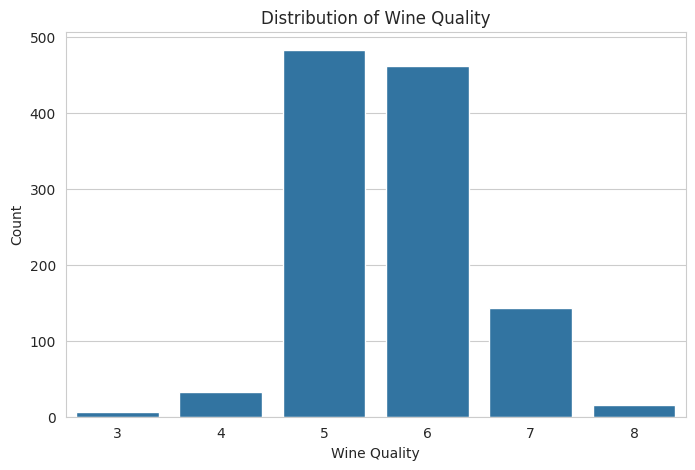

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(x='quality', data=df)

plt.title('Distribution of Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Count')

plt.show()

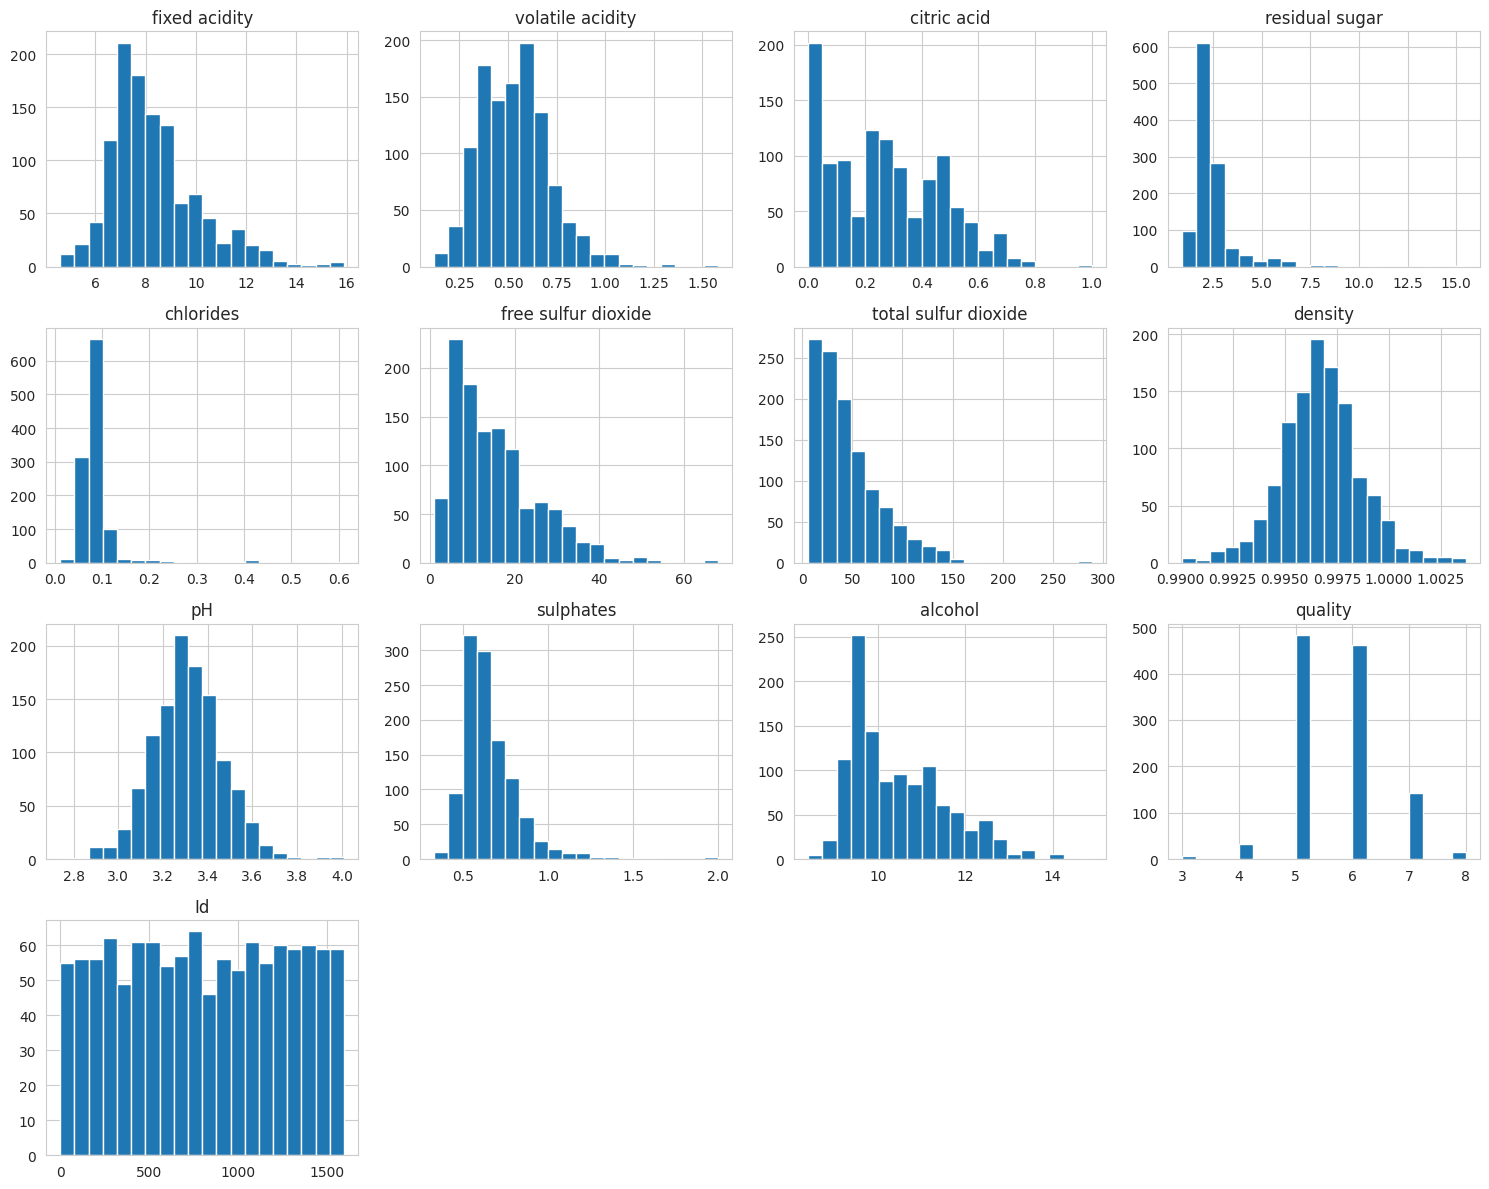

In [ ]:
df.hist(figsize=(15,12), bins=20)

plt.tight_layout()
plt.show()

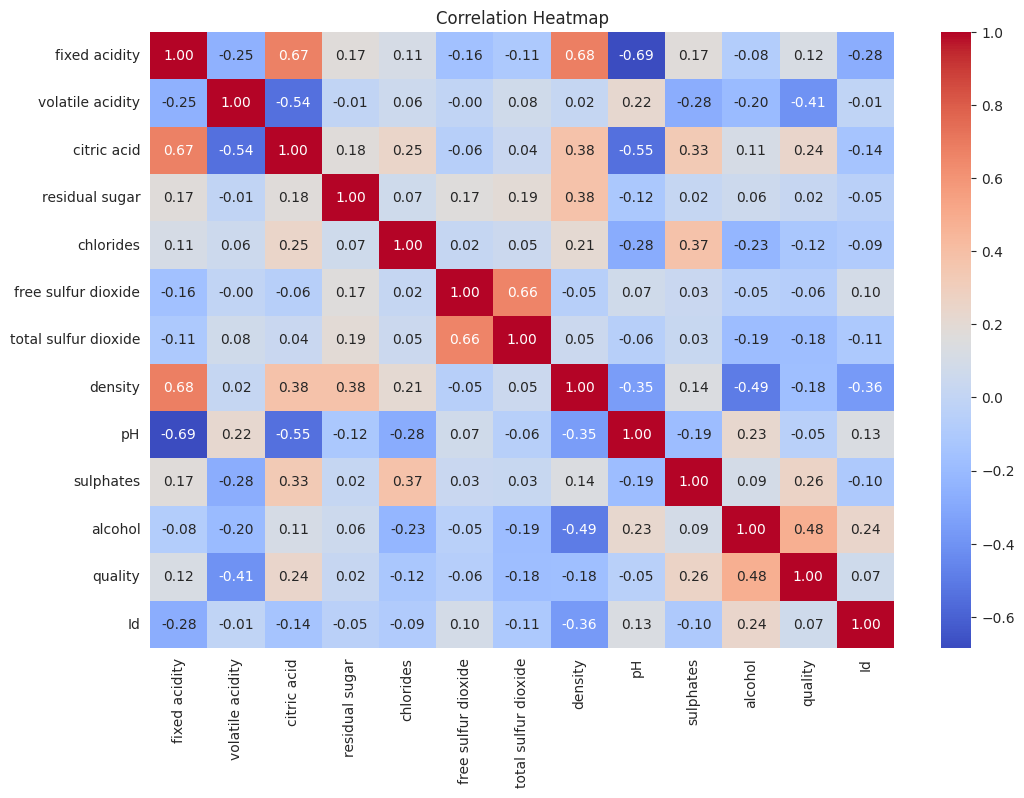

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")

plt.show()

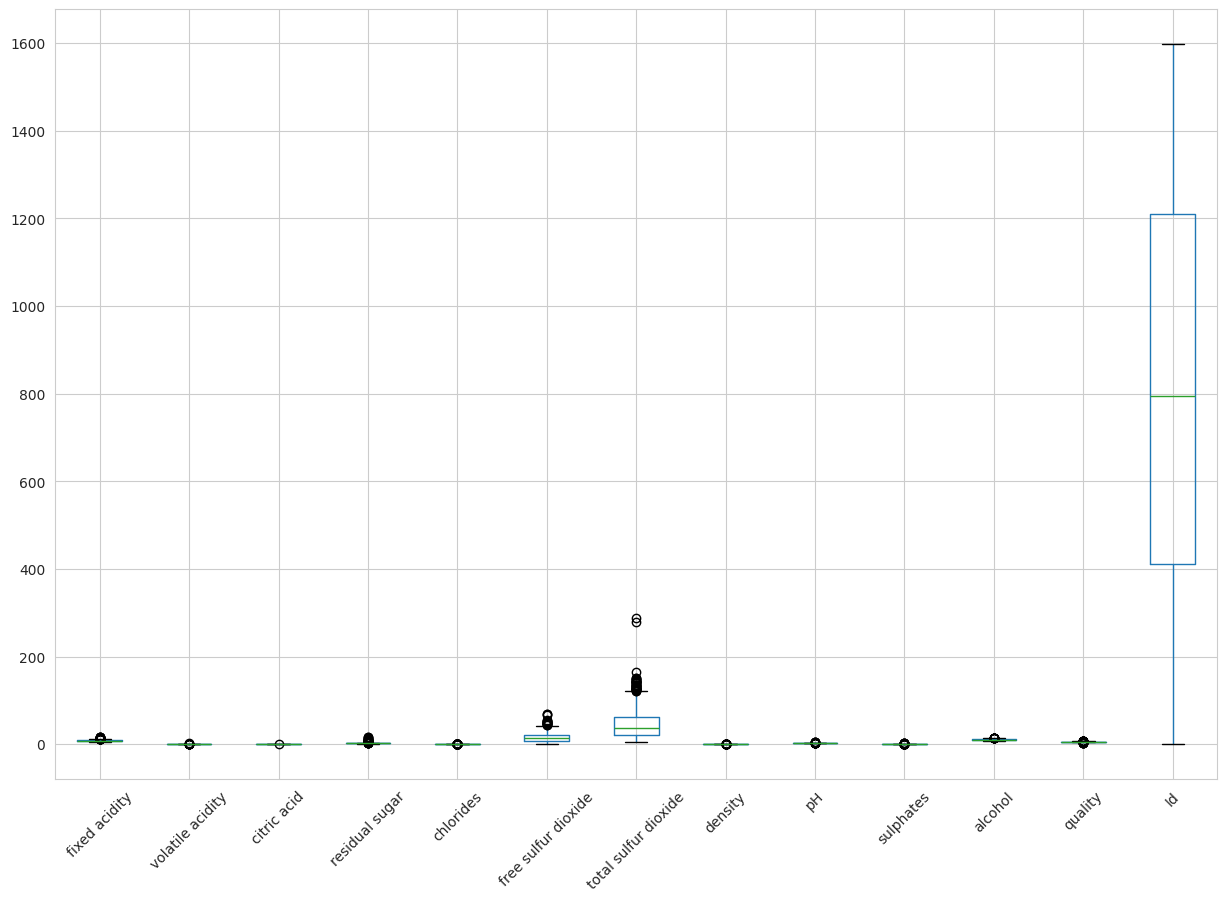

In [ ]:
plt.figure(figsize=(15,10))

df.boxplot(rot=45)

plt.show()

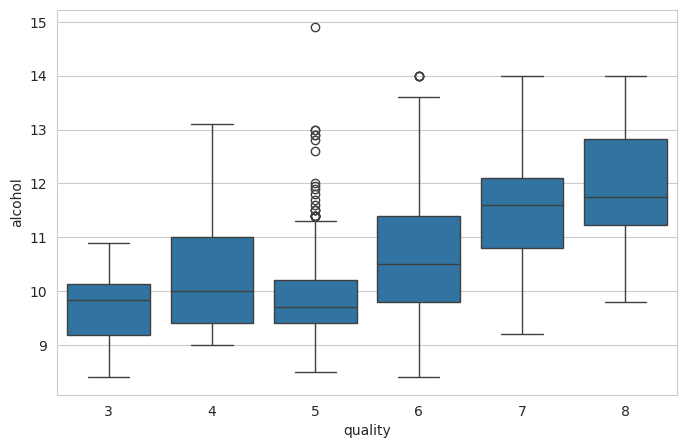

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x='quality', y='alcohol', data=df)

plt.show()

Model trainig after the data visaulization

In [ ]:
X = df.drop(["quality", "Id"], axis=1)
y = df["quality"]
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # if classification
)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

1. first let us check for logistic regression

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy: 0.6244541484716157
Precision: 0.5877153737415746
Recall: 0.6244541484716157
F1 Score: 0.6036519509574253


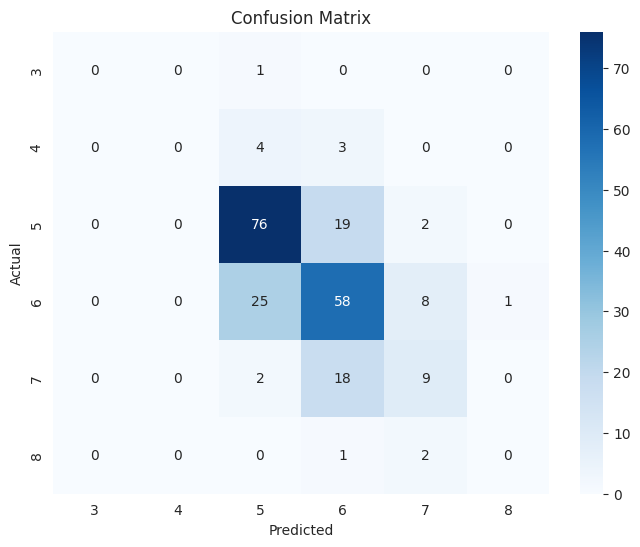

In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr = LogisticRegression(max_iter=1000)

# Train the model
lr.fit(X_train_scaled, y_train)

# Make predictions
y_pred = lr.predict(X_test_scaled)

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()
results = []

results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
})

2. Decision Trees

Accuracy : 0.62882096069869
Precision: 0.6207875263152729
Recall   : 0.62882096069869
F1 Score : 0.6245028841858681
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.17      0.14      0.15         7
           5       0.68      0.71      0.70        97
           6       0.63      0.61      0.62        92
           7       0.58      0.62      0.60        29
           8       0.00      0.00      0.00         3

    accuracy                           0.63       229
   macro avg       0.34      0.35      0.34       229
weighted avg       0.62      0.63      0.62       229



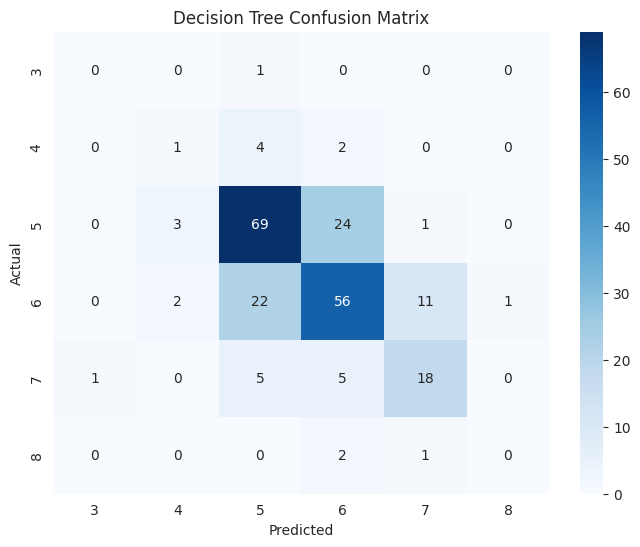

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, average='weighted')
recall_dt = recall_score(y_test, y_pred_dt, average='weighted')
f1_dt = f1_score(y_test, y_pred_dt, average='weighted')

print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1 Score :", f1_dt)
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt))

#the confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()
results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1 Score": f1_dt
})

3. Random forest

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Accuracy : 0.7161572052401747
Precision: 0.682174663328421
Recall   : 0.7161572052401747
F1 Score : 0.6939095602645294
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.74      0.85      0.79        97
           6       0.69      0.74      0.71        92
           7       0.74      0.48      0.58        29
           8       0.00      0.00      0.00         3

    accuracy                           0.72       229
   macro avg       0.36      0.34      0.35       229
weighted avg       0.68      0.72      0.69       229



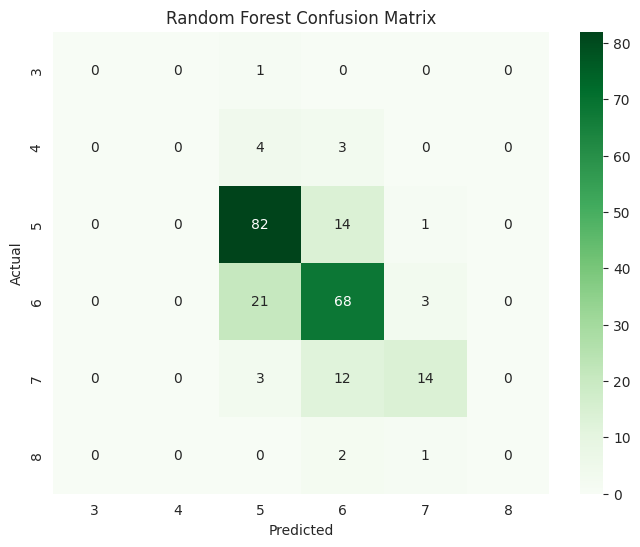

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))
#confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()
results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1 Score": f1_dt
})

4. SVM it is now

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Accuracy : 0.6681222707423581
Precision: 0.6397101548869147
Recall   : 0.6681222707423581
F1 Score : 0.6420216264828293
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.73      0.80      0.76        97
           6       0.61      0.72      0.66        92
           7       0.69      0.31      0.43        29
           8       0.00      0.00      0.00         3

    accuracy                           0.67       229
   macro avg       0.34      0.31      0.31       229
weighted avg       0.64      0.67      0.64       229



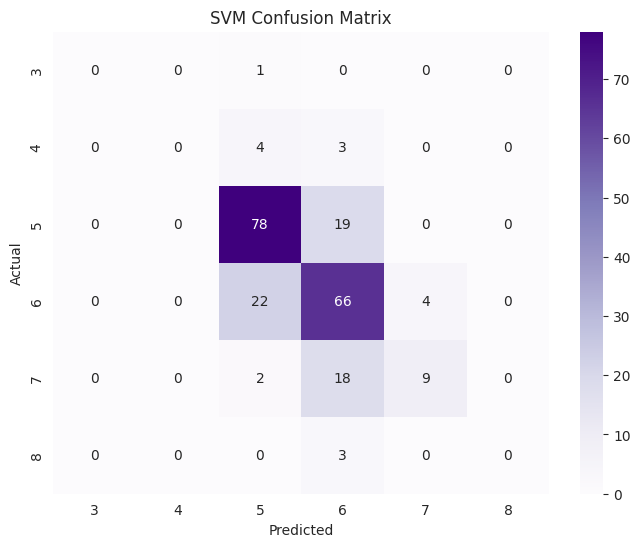

In [ ]:
from sklearn.svm import SVC
svm = SVC(
    kernel='rbf',
    random_state=42
)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, average='weighted')
recall_svm = recall_score(y_test, y_pred_svm, average='weighted')
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')

print("Accuracy :", accuracy_svm)
print("Precision:", precision_svm)
print("Recall   :", recall_svm)
print("F1 Score :", f1_svm)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_svm))
# the confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()
results.append({
    "Model": "Support Vector Machine",
    "Accuracy": accuracy_svm,
    "Precision": precision_svm,
    "Recall": recall_svm,
    "F1 Score": f1_svm
})


5. KNN

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Accuracy : 0.5764192139737991
Precision: 0.553218807503227
Recall   : 0.5764192139737991
F1 Score : 0.5632480360996469
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.68      0.68      0.68        97
           6       0.53      0.61      0.57        92
           7       0.42      0.34      0.38        29
           8       0.00      0.00      0.00         3

    accuracy                           0.58       229
   macro avg       0.27      0.27      0.27       229
weighted avg       0.55      0.58      0.56       229



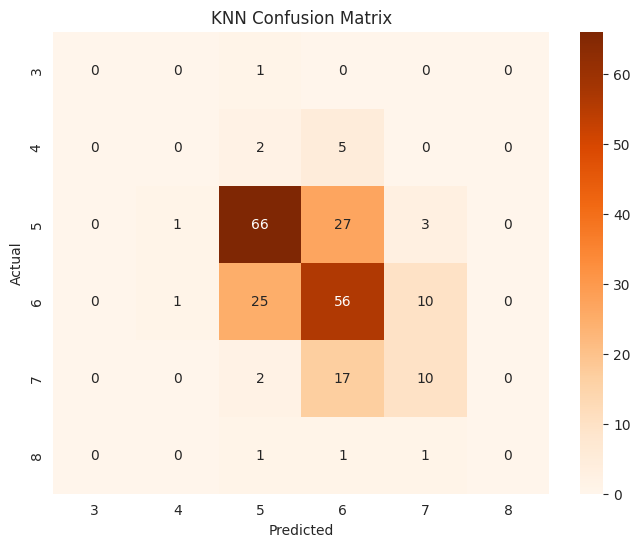

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, average='weighted')
recall_knn = recall_score(y_test, y_pred_knn, average='weighted')
f1_knn = f1_score(y_test, y_pred_knn, average='weighted')

print("Accuracy :", accuracy_knn)
print("Precision:", precision_knn)
print("Recall   :", recall_knn)
print("F1 Score :", f1_knn)
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_knn))
# Confusion Matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()
results.append({
    "Model": "K-Nearest Neighbors",
    "Accuracy": accuracy_knn,
    "Precision": precision_knn,
    "Recall": recall_knn,
    "F1 Score": f1_knn
})

6. Gradient Boost

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Accuracy : 0.6593886462882096
Precision: 0.6319964212977313
Recall   : 0.6593886462882096
F1 Score : 0.6436382492950473
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.70      0.80      0.75        97
           6       0.65      0.64      0.64        92
           7       0.58      0.48      0.53        29
           8       0.00      0.00      0.00         3

    accuracy                           0.66       229
   macro avg       0.32      0.32      0.32       229
weighted avg       0.63      0.66      0.64       229



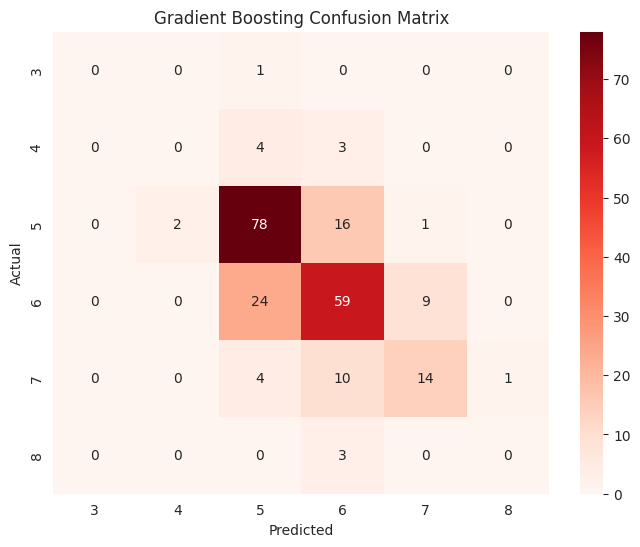

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb, average='weighted')
recall_gb = recall_score(y_test, y_pred_gb, average='weighted')
f1_gb = f1_score(y_test, y_pred_gb, average='weighted')

print("Accuracy :", accuracy_gb)
print("Precision:", precision_gb)
print("Recall   :", recall_gb)
print("F1 Score :", f1_gb)
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_gb))
# confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gradient Boosting Confusion Matrix")
plt.show()
results.append({
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_gb,
    "Precision": precision_gb,
    "Recall": recall_gb,
    "F1 Score": f1_gb
})

7. XG Boost

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Accuracy : 0.6768558951965066
Precision: 0.6587442221181978
Recall   : 0.6768558951965066
F1 Score : 0.6655701153508075
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.69      0.79      0.74        97
           6       0.67      0.65      0.66        92
           7       0.71      0.59      0.64        29
           8       0.33      0.33      0.33         3

    accuracy                           0.68       229
   macro avg       0.40      0.39      0.40       229
weighted avg       0.66      0.68      0.67       229



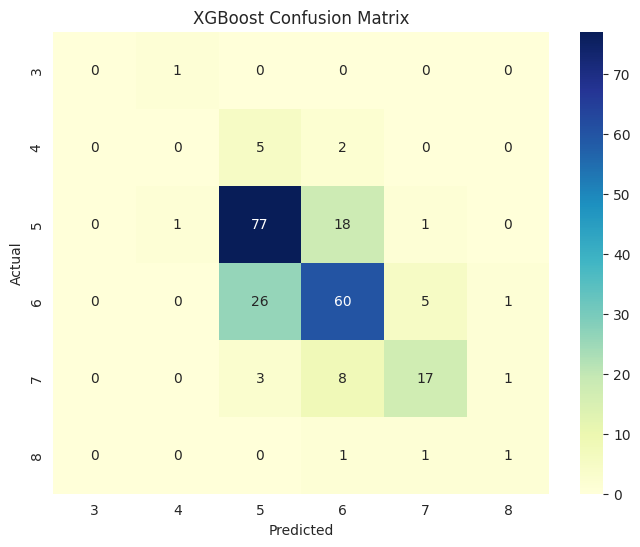

In [ ]:
!pip install xgboost
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
xgb = XGBClassifier(
    objective='multi:softmax',
    num_class=len(label_encoder.classes_),
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric='mlogloss'
)
xgb.fit(X_train, y_train_encoded)
y_pred_xgb_encoded = xgb.predict(X_test)
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_encoded)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb, average='weighted')
recall_xgb = recall_score(y_test, y_pred_xgb, average='weighted')
f1_xgb = f1_score(y_test, y_pred_xgb, average='weighted')

print("Accuracy :", accuracy_xgb)
print("Precision:", precision_xgb)
print("Recall   :", recall_xgb)
print("F1 Score :", f1_xgb)
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_xgb))
# confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.show()
results.append({
    "Model": "XGBoost",
    "Accuracy": accuracy_xgb,
    "Precision": precision_xgb,
    "Recall": recall_xgb,
    "F1 Score": f1_xgb
})

COMPARISON TABLE

In [ ]:
import pandas as pd

results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Support Vector Machine",
        "K-Nearest Neighbors",
        "Gradient Boosting",
        "XGBoost"
    ],
    "Accuracy": [
        0.62882096069869,
        0.6200873362445415,
        0.7030567685589519,
        0.6724890829694323,
        0.5764192139737991,
        0.6506550218340611,
        0.6899563318777293
    ],
    "Precision": [
        0.5923575092934451,
        0.6067991540632965,
        0.6686659974287666,
        0.6424119750307667,
        0.5485765014773125,
        0.6249327399442197,
        0.6676454154731183
    ],
    "Recall": [
        0.62882096069869,
        0.6200873362445415,
        0.7030567685589519,
        0.6724890829694323,
        0.5764192139737991,
        0.6506550218340611,
        0.6899563318777293
    ],
    "F1 Score": [
        0.6069409703085034,
        0.6098928544067593,
        0.6816820650039267,
        0.6466994101555467,
        0.5617654191589845,
        0.6365203323143082,
        0.6740706527824432
    ]
})

results_df = results_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
results_df = results_df.round(4)

print(results_df)

                    Model  Accuracy  Precision  Recall  F1 Score
0           Random Forest    0.7031     0.6687  0.7031    0.6817
1                 XGBoost    0.6900     0.6676  0.6900    0.6741
2  Support Vector Machine    0.6725     0.6424  0.6725    0.6467
3       Gradient Boosting    0.6507     0.6249  0.6507    0.6365
4     Logistic Regression    0.6288     0.5924  0.6288    0.6069
5           Decision Tree    0.6201     0.6068  0.6201    0.6099
6     K-Nearest Neighbors    0.5764     0.5486  0.5764    0.5618


Since the tuning didnt work in favour we will keep the baseline model of random forest

**Now we will plot in order to display the feature importance **

                 Feature  Importance
10               alcohol    0.150212
9              sulphates    0.115907
1       volatile acidity    0.106638
6   total sulfur dioxide    0.097958
7                density    0.087983
4              chlorides    0.078689
0          fixed acidity    0.077977
2            citric acid    0.077131
8                     pH    0.077033
3         residual sugar    0.065486
5    free sulfur dioxide    0.064986


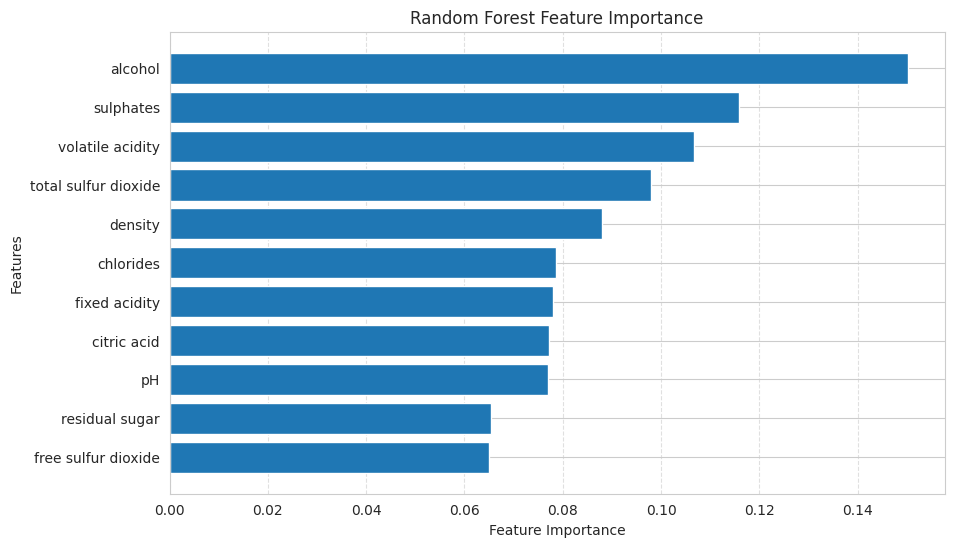

In [ ]:
# Import required libraries
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

# Train the final Random Forest model (Baseline Model)
rf_final = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_final.fit(X_train, y_train)

# Calculate Feature Importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_final.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance values
print(feature_importance)

# Plot Feature Importance
plt.figure(figsize=(10,6))
plt.barh(feature_importance["Feature"],
         feature_importance["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

Cross validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    X,
    y,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

print("Cross Validation Scores:", scores)
print("Mean Accuracy:", np.mean(scores))
print("Standard Deviation:", np.std(scores))

Cross Validation Scores: [0.6419214  0.6419214  0.68995633 0.65350877 0.71052632]
Mean Accuracy: 0.6675668428713706
Standard Deviation: 0.02778421364327342


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest with class weights
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

rf_balanced.fit(X_train, y_train)

# Predictions
y_pred_balanced = rf_balanced.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error
)
import numpy as np

accuracy_bal = accuracy_score(y_test, y_pred_balanced)
precision_bal = precision_score(
    y_test,
    y_pred_balanced,
    average='weighted',
    zero_division=0
)

recall_bal = recall_score(
    y_test,
    y_pred_balanced,
    average='weighted',
    zero_division=0
)

f1_bal = f1_score(
    y_test,
    y_pred_balanced,
    average='weighted',
    zero_division=0
)

rmse_bal = np.sqrt(mean_squared_error(y_test, y_pred_balanced))

print("Balanced Random Forest Results")
print("-"*40)
print(f"Accuracy : {accuracy_bal:.4f}")
print(f"Precision: {precision_bal:.4f}")
print(f"Recall   : {recall_bal:.4f}")
print(f"F1 Score : {f1_bal:.4f}")
print(f"RMSE     : {rmse_bal:.4f}")

Balanced Random Forest Results
----------------------------------------
Accuracy : 0.6725
Precision: 0.6541
Recall   : 0.6725
F1 Score : 0.6559
RMSE     : 0.6674


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_balanced,
    zero_division=0
))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.70      0.80      0.75        97
           6       0.63      0.66      0.65        92
           7       0.74      0.48      0.58        29
           8       1.00      0.33      0.50         3

    accuracy                           0.67       229
   macro avg       0.51      0.38      0.41       229
weighted avg       0.65      0.67      0.66       229



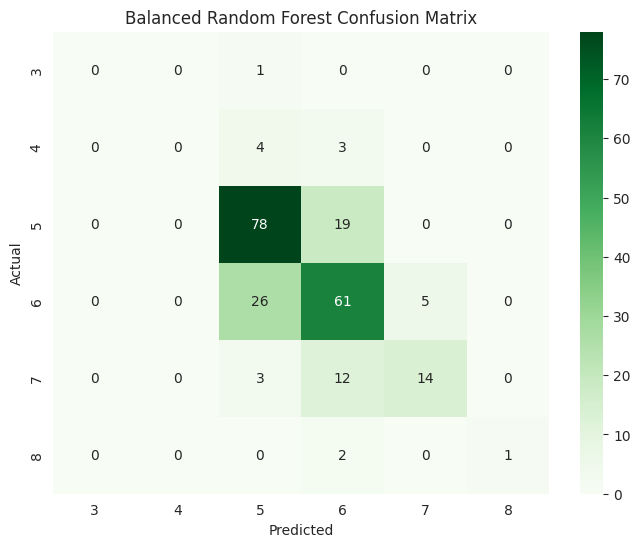

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Balanced Random Forest Confusion Matrix")
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores_bal = cross_val_score(
    rf_balanced,
    X,
    y,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

print("Cross Validation Scores:", scores_bal)
print("Mean Accuracy:", scores_bal.mean())
print("Standard Deviation:", scores_bal.std())

Cross Validation Scores: [0.59825328 0.63755459 0.70305677 0.6754386  0.69736842]
Mean Accuracy: 0.662334329272964
Standard Deviation: 0.039440699002316816


In [ ]:
comparison = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "RMSE"],
    "Baseline Random Forest": [
        accuracy_rf,
        precision_rf,
        recall_rf,
        f1_rf,
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    "Balanced Random Forest": [
        accuracy_bal,
        precision_bal,
        recall_bal,
        f1_bal,
        rmse_bal
    ]
}

comparison_df = pd.DataFrame(comparison)
print(comparison_df)

      Metric  Baseline Random Forest  Balanced Random Forest
0   Accuracy                0.716157                0.672489
1  Precision                0.682175                0.654051
2     Recall                0.716157                0.672489
3   F1 Score                0.693910                0.655916
4       RMSE                0.644086                0.667394


In [ ]:
from sklearn.metrics import f1_score

macro_f1_baseline = f1_score(
    y_test,
    y_pred_rf,
    average='macro',
    zero_division=0
)

macro_f1_balanced = f1_score(
    y_test,
    y_pred_balanced,
    average='macro',
    zero_division=0
)

print("Baseline Macro F1 :", round(macro_f1_baseline, 4))
print("Balanced Macro F1:", round(macro_f1_balanced, 4))

Baseline Macro F1 : 0.3473
Balanced Macro F1: 0.4125


In [ ]:
import joblib

joblib.dump(rf_final, "wine_quality_model.pkl")

['wine_quality_model.pkl']

In [ ]:
feature_names = list(X.columns)

joblib.dump(feature_names, "feature_names.pkl")

['feature_names.pkl']

In [ ]:
from google.colab import files

files.download("wine_quality_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>